In [1]:
import time
import requests
import numpy as np
import pandas as pd
from pathlib import Path

In [2]:
input_csv = Path(
    "/Users/andrewweiland/Chopra_Lab_Research/"
    "moo_selection/curated_200_approved_drug_molecules.csv"
)

compounds = pd.read_csv(input_csv)

compounds.head()

,candidate_id,chembl_id,preferred_name,smiles,standard_inchi_key,molecular_formula,molecular_weight,alogp,polar_surface_area,hbond_acceptors,...,first_approval_year,max_phase,oral,parenteral,topical,prodrug,black_box_warning,source_database,source_record_url,source_retrieved_date
0,MOO001,CHEMBL2205807,ABAMETAPIR,Cc1ccc(-c2ccc(C)cn2)nc1,PTRATZCAGVBFIQ-UHFFFAOYSA-N,C12H12N2,184.24,2.76,25.78,2,...,2020.0,4,False,False,True,False,False,ChEMBL,https://www.ebi.ac.uk/chembl/explore/compound/...,2026-08-29
1,MOO002,CHEMBL271227,ABIRATERONE ACETATE,CC(=O)O[C@H]1CC[C@@]2(C)C(=CC[C@@H]3[C@@H]2CC[...,UVIQSJCZCSLXRZ-UBUQANBQSA-N,C26H33NO2,391.56,5.97,39.19,3,...,2011.0,4,True,False,False,True,False,ChEMBL,https://www.ebi.ac.uk/chembl/explore/compound/...,2026-08-29
2,MOO003,CHEMBL1201327,ACETRIZOIC ACID,CC(=O)Nc1c(I)cc(I)c(C(=O)O)c1I,GNOGSFBXBWBTIG-UHFFFAOYSA-N,C9H6I3NO3,556.86,3.16,66.40,2,...,1982.0,4,False,False,True,False,False,ChEMBL,https://www.ebi.ac.uk/chembl/explore/compound/...,2026-08-29
3,MOO004,CHEMBL3940890,ACORAMIDIS,Cc1n[nH]c(C)c1CCCOc1cc(C(=O)O)ccc1F,WBFUHHBPNXWNCC-UHFFFAOYSA-N,C15H17FN2O3,292.31,2.88,75.21,3,...,2024.0,4,True,False,False,False,False,ChEMBL,https://www.ebi.ac.uk/chembl/explore/compound/...,2026-08-29
4,MOO005,CHEMBL634,ALFENTANIL,CCC(=O)N(c1ccccc1)C1(COC)CCN(CCn2nnn(CC)c2=O)CC1,IDBPHNDTYPBSNI-UHFFFAOYSA-N,C21H32N6O3,416.53,1.38,85.49,8,...,1986.0,4,False,True,False,False,True,ChEMBL,https://www.ebi.ac.uk/chembl/explore/compound/...,2026-08-29


In [3]:
# Confirms both Docker services are running and healthy
boiledegg_url = "http://localhost:8103"
kinasepred_url = "http://localhost:18013"

print(requests.get(f"{boiledegg_url}/health", timeout=10).json())
print(requests.get(f"{kinasepred_url}/health", timeout=10).json())

{'status': 'Healthy', 'message': 'BoiledEgg is running'}
{'status': 'Healthy', 'message': 'KinasePred is running'}


In [4]:
test_smiles = "CCO"

boiledegg_response = requests.post(
    f"{boiledegg_url}/smi",
    json={"smiles": test_smiles, "property": ["WLogP"]},
    timeout=60,
)

kinase_response = requests.post(
    f"{kinasepred_url}/smi",
    json={
        "smiles": test_smiles,
        "property": ["Kinase Activity Prediction"],
    },
    timeout=300,
)

print(boiledegg_response.status_code)
print(boiledegg_response.json())

print(kinase_response.status_code)
print(kinase_response.json())

200
{'smiles': 'CCO', 'status': 'success', 'results': {'WLogP': {'property': 'WLogP', 'status': 'success', 'results': -0.0, 'error': None}}, 'error': None}
200
{'smiles': 'CCO', 'status': 'success', 'results': {'Kinase Activity Prediction': {'property': 'Kinase Activity Prediction', 'status': 'success', 'results': 2.206597309850622e-05, 'error': None}}, 'error': None}


In [4]:
def extract_prediction(body, expected_property=None):
    if body.get("status") != "success":
        raise RuntimeError(f"Model returned an error: {body}")

    results = body.get("results", {})

    if expected_property is not None:
        if expected_property not in results:
            raise KeyError(
                f"Expected property '{expected_property}' not found. "
                f"Available properties: {list(results)}"
            )
        result = results[expected_property]
    elif len(results) == 1:
        result = next(iter(results.values()))
    else:
        raise KeyError(f"Could not identify a unique result: {body}")

    # Different services use different value keys.
    value = result.get("results")

    if value is None:
        value = result.get("prediction")

    if value is None:
        raise ValueError(f"No numeric prediction found: {result}")

    return float(value)

In [5]:
def query_models(smiles):
    # BoiledEgg returns WLogP as a lightweight continuous property.
    boiledegg_response = requests.post(
        f"{boiledegg_url}/smi",
        json={"smiles": smiles, "property": ["WLogP"]},
        timeout=60,
    )
    boiledegg_response.raise_for_status()

    # KinasePred needs the requested property name.
    kinase_response = requests.post(
        f"{kinasepred_url}/smi",
        json={
            "smiles": smiles,
            "property": ["Kinase Activity Prediction"],
        },
        timeout=300,
    )
    kinase_response.raise_for_status()

    boiledegg_body = boiledegg_response.json()
    kinase_body = kinase_response.json()

    wlogp = extract_prediction(
        boiledegg_body,
        expected_property="WLogP",
    )

    kinase_activity = extract_prediction(
        kinase_body,
        expected_property="Kinase Activity Prediction",
    )

    return wlogp, kinase_activity

In [6]:
query_models("CCO")

(-0.0, 2.206597309850622e-05)

In [8]:
prediction_rows = []

for index, row in compounds.iterrows():
    smiles = row["smiles"]

    print(f"{index + 1}/{len(compounds)}: {smiles}")

    try:
        wlogp, kinase_activity = query_models(smiles)

        prediction_rows.append({
            "smiles": smiles,
            "WLogP": wlogp,
            "kinase_activity": kinase_activity,
            "status": "success",
            "error": None,
        })

    except Exception as exc:
        prediction_rows.append({
            "smiles": smiles,
            "WLogP": np.nan,
            "kinase_activity": np.nan,
            "status": "error",
            "error": str(exc),
        })

    # Small pause to avoid immediately hitting the services again.
    time.sleep(0.05)

1/200: Cc1ccc(-c2ccc(C)cn2)nc1
2/200: CC(=O)O[C@H]1CC[C@@]2(C)C(=CC[C@@H]3[C@@H]2CC[C@]2(C)C(c4cccnc4)=CC[C@@H]32)C1
3/200: CC(=O)Nc1c(I)cc(I)c(C(=O)O)c1I
4/200: Cc1n[nH]c(C)c1CCCOc1cc(C(=O)O)ccc1F
5/200: CCC(=O)N(c1ccccc1)C1(COC)CCN(CCn2nnn(CC)c2=O)CC1
6/200: COc1cc2nc(N(C)CCCNC(=O)C3CCCO3)nc(N)c2cc1OC
7/200: CN(C)c1nc(N(C)C)nc(N(C)C)n1
8/200: CC[N+](CC)(CCNC(=O)C(=O)NCC[N+](CC)(CC)Cc1ccccc1Cl)Cc1ccccc1Cl
9/200: CC(C)(C)C(=O)OCOC(=O)[C@@H]1N2C(=O)[C@@H](/N=C/N3CCCCCC3)[C@H]2SC1(C)C
10/200: N=C(N)NC(=O)c1nc(Cl)c(N)nc1N
11/200: CCN(CC)Cc1cc(Nc2ccnc3cc(Cl)ccc23)ccc1O
12/200: Cn1cnc([N+](=O)[O-])c1Sc1ncnc2[nH]cnc12
13/200: COC(=O)OCOc1c2n(ccc1=O)N([C@@H]1c3ccccc3SCc3c1ccc(F)c3F)[C@@H]1COCCN1C2=O
14/200: CC(C)NC(=O)COc1cccc(-c2nc(Nc3ccc4[nH]ncc4c3)c3ccccc3n2)c1
15/200: CC(C)(CCCCCC(O)CCCCCC(C)(C)C(=O)O)C(=O)O
16/200: CC(=O)Nc1ccc(OC(=O)c2ccccc2OC(C)=O)cc1
17/200: C=C(c1ccc(C(=O)O)cc1)c1cc2c(cc1C)C(C)(C)CCC2(C)C
18/200: c1ccc(-c2ccc(C(c3ccccc3)n3ccnc3)cc2)cc1
19/200: CC(C)NCC(O)COc1ccc(COCC

In [9]:
predictions = pd.DataFrame(prediction_rows)

predictions.head()

,smiles,WLogP,kinase_activity,status,error
0,Cc1ccc(-c2ccc(C)cn2)nc1,2.76,1.780777e-05,success,None
1,CC(=O)O[C@H]1CC[C@@]2(C)C(=CC[C@@H]3[C@@H]2CC[...,5.97,2.764342e-06,success,None
2,CC(=O)Nc1c(I)cc(I)c(C(=O)O)c1I,3.16,5.716454e-03,success,None
3,Cc1n[nH]c(C)c1CCCOc1cc(C(=O)O)ccc1F,2.88,8.685445e-01,success,None
4,CCC(=O)N(c1ccccc1)C1(COC)CCN(CCn2nnn(CC)c2=O)CC1,1.38,3.256349e-12,success,None


In [10]:
prediction_output = Path(
    "/Users/andrewweiland/Chopra_Lab_Research/"
    "moo_selection/live_predictions_no_cache.csv"
)
predictions.to_csv(prediction_output, index=False)
predictions.head()

,smiles,WLogP,kinase_activity,status,error
0,Cc1ccc(-c2ccc(C)cn2)nc1,2.76,1.780777e-05,success,None
1,CC(=O)O[C@H]1CC[C@@]2(C)C(=CC[C@@H]3[C@@H]2CC[...,5.97,2.764342e-06,success,None
2,CC(=O)Nc1c(I)cc(I)c(C(=O)O)c1I,3.16,5.716454e-03,success,None
3,Cc1n[nH]c(C)c1CCCOc1cc(C(=O)O)ccc1F,2.88,8.685445e-01,success,None
4,CCC(=O)N(c1ccccc1)C1(COC)CCN(CCn2nnn(CC)c2=O)CC1,1.38,3.256349e-12,success,None


In [11]:
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting

valid = predictions.dropna(subset=["WLogP", "kinase_activity"]).copy()
F = np.column_stack([
    valid["WLogP"].to_numpy(),
    -valid["kinase_activity"].to_numpy(),
])
front = NonDominatedSorting().do(F, only_non_dominated_front=True)
pareto = valid.iloc[front].copy()
pareto.to_csv(
    "/Users/andrewweiland/Chopra_Lab_Research/"
    "moo_selection/live_pareto_front.csv",
    index=False,
)
print(f"Pareto compounds: {len(pareto)}")
pareto

Pareto compounds: 6


,smiles,WLogP,kinase_activity,status,error
66,Fc1ccc(-c2ccc3c(c2)[nH]c2ccncc23)cn1,3.92,1.000000e+00,success,None
71,O=c1[nH]cnc2c([C@@H]3N[C@H](CO)[C@@H](O)[C@H]3...,-2.02,9.999722e-01,success,None
82,N=C(N)c1ccc(/C=C/c2ccc(C(=N)N)cc2O)cc1,2.13,9.999921e-01,success,None
113,OC[C@H]1NC[C@H](O)[C@@H](O)[C@H]1O,-2.97,5.080588e-08,success,None
152,C[C@H]1CNC(=O)c2cnn3ccc(nc23)N[C@H](C)c2cc(F)c...,2.55,9.999996e-01,success,None
162,CN[C@@H]1[C@H](O)[C@H](NC)[C@H]2O[C@@]3(O)C(=O...,-2.93,2.248882e-05,success,None


In [15]:
front

array([ 66,  71,  82, 113, 152, 162])

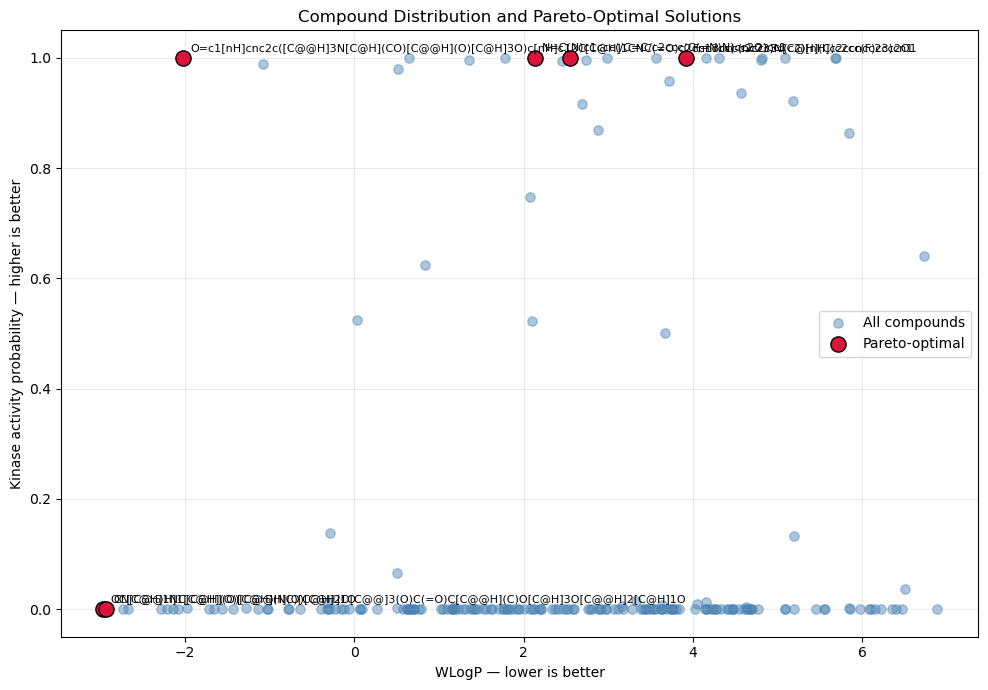

In [12]:
import matplotlib.pyplot as plt

# Use valid predictions only
plot_df = predictions.dropna(
    subset=["WLogP", "kinase_activity"]
).copy()

# Recalculate Pareto indices if needed
F = np.column_stack([
    plot_df["WLogP"].to_numpy(),          # minimize
    -plot_df["kinase_activity"].to_numpy() # maximize activity
])

pareto_indices = NonDominatedSorting().do(
    F,
    only_non_dominated_front=True,
)

pareto_df = plot_df.iloc[pareto_indices].copy()

# Plot all compounds
fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(
    plot_df["WLogP"],
    plot_df["kinase_activity"],
    s=45,
    alpha=0.45,
    color="steelblue",
    label="All compounds",
)

# Highlight Pareto-optimal compounds
ax.scatter(
    pareto_df["WLogP"],
    pareto_df["kinase_activity"],
    s=120,
    color="crimson",
    edgecolor="black",
    linewidth=1,
    label="Pareto-optimal",
    zorder=3,
)

# Label Pareto compounds
for _, compound in pareto_df.iterrows():
    label = compound.get(
        "preferred_name",
        compound.get("candidate_id", compound["smiles"])
    )

    ax.annotate(
        str(label),
        (
            compound["WLogP"],
            compound["kinase_activity"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

ax.set_xlabel("WLogP — lower is better")
ax.set_ylabel("Kinase activity probability — higher is better")
ax.set_title("Compound Distribution and Pareto-Optimal Solutions")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()